# ORBITGUARD Stage 5: Model evaluation and performance comparison

This notebook loads the saved Stage 4 inference pipelines and evaluates them on the official held-out test split. It does not fit, retrain, or tune any model. The pipeline includes the Stage 3 preprocessing step. Results and figures are saved under `reports/evaluation/` and `reports/figures/` for later reuse.

Run the notebook from top to bottom in VS Code or Google Colab with the Stage 3 data and Stage 4 model artifacts available in the project.

## 1. Evaluation terms in simple English

The positive class is **anomalous (1)** and the negative class is **normal (0)**.

- **True positive (TP):** an anomalous segment correctly flagged as anomalous.
- **True negative (TN):** a normal segment correctly identified as normal.
- **False positive (FP):** a normal segment incorrectly flagged as anomalous. Operators may spend time investigating these false alarms.
- **False negative (FN):** an anomalous segment missed and predicted as normal. In satellite monitoring, a missed anomaly can be especially costly.
- **Accuracy:** the fraction of all predictions that are correct. It can look high if a model mostly predicts the majority normal class.
- **Precision:** among segments flagged anomalous, the fraction that really are anomalous. Higher precision means fewer false alarms.
- **Recall:** among all truly anomalous segments, the fraction the model detects. Higher anomaly recall means fewer missed anomalies.
- **F1-score:** a balance of precision and recall, summarized by their harmonic mean. It is low if either precision or recall is low.
- **ROC-AUC:** measures how well anomaly scores rank anomalous records above normal ones across classification thresholds. `0.5` is chance ranking and `1.0` is perfect ranking.
- **PR-AUC:** area under the precision-recall curve. It focuses on anomaly detection and is useful when anomalies are less common. This notebook reports trapezoidal area; average precision is included as a separate metric because it uses a different calculation.

**Which metric matters most?** Anomaly recall deserves special attention because low recall means false negatives—real satellite anomalies that go undetected. However, maximizing recall can increase false positives, so precision and F1 should be considered alongside it. Accuracy alone is not enough for this imbalanced dataset: many correct normal predictions can hide missed anomalies.

## 2. Locate saved models and held-out data

The evaluator requires separate Stage 4 artifacts for Decision Tree, Random Forest, baseline XGBoost, and tuned XGBoost. It checks the feature contract and embedded Stage 3 preprocessing pipeline. If a required artifact is missing or incompatible, it stops with the missing file or validation error rather than training a replacement.

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import display, Image

current_path = Path.cwd().resolve()
if current_path.name.lower() == "notebooks":
    current_path = current_path.parent
PROJECT_ROOT = next(
    (candidate for candidate in (current_path, *current_path.parents)
     if (candidate / "src" / "evaluate.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find ORBITGUARD (src/evaluate.py). Open this notebook from "
        "the project or clone the repository in Google Colab."
    )
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluate import evaluate_saved_models

MODEL_DIR = PROJECT_ROOT / "models"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports" / "evaluation"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

evaluation = evaluate_saved_models(
    model_dir=MODEL_DIR,
    processed_dir=PROCESSED_DIR,
    report_dir=REPORT_DIR,
    figures_dir=FIGURES_DIR,
    raw_dataset_path=PROJECT_ROOT / "data" / "raw" / "dataset.csv",
)

print("Evaluation complete. No model was fitted or tuned in this notebook.")
print("Test set class counts (0=Normal, 1=Anomalous):", evaluation["test_class_counts"])
print("Loaded models:", list(evaluation["results"]))

Evaluation complete. No model was fitted or tuned in this notebook.
Test set class counts (0=Normal, 1=Anomalous): {0: 416, 1: 113}
Loaded models: ['Decision Tree', 'Random Forest', 'XGBoost baseline', 'Tuned XGBoost']


## 3. Compare held-out test performance

Every row below comes from predictions on the same official test records. `recall_anomaly` is shown near the start of the table because missed anomalies are important. ROC-AUC and PR-AUC use probabilities; precision, recall, F1, accuracy, and confusion counts use the saved classifiers' default 0.5 decision threshold. Models are ranked by anomaly recall, with F1 and then PR-AUC as tie-breakers. This is an explicit comparison rule, not a claim that one model is universally best.

In [2]:
comparison = evaluation["comparison"]
display(comparison.round(4))
best_row = comparison.iloc[0]
print(
    "Best by the stated rule (anomaly recall, then F1, then PR-AUC): "
    f"{evaluation['best_model']} — recall={best_row['recall_anomaly']:.4f}, "
    f"F1={best_row['f1_anomaly']:.4f}, PR-AUC={best_row['pr_auc']:.4f}."
)

,model,accuracy,precision_anomaly,recall_anomaly,f1_anomaly,roc_auc,pr_auc,average_precision,true_negative,false_positive,false_negative,true_positive
0,Random Forest,0.9679,0.9706,0.8761,0.9209,0.9886,0.9687,0.9684,413,3,14,99
1,Decision Tree,0.9490,0.8839,0.8761,0.8800,0.9224,0.8932,0.8009,403,13,14,99
2,XGBoost baseline,0.9641,0.9608,0.8673,0.9116,0.9873,0.9641,0.9643,412,4,15,98
3,Tuned XGBoost,0.9584,0.9333,0.8673,0.8991,0.9900,0.9693,0.9695,409,7,15,98


Best by the stated rule (anomaly recall, then F1, then PR-AUC): Random Forest — recall=0.8761, F1=0.9209, PR-AUC=0.9687.


## 4. Confusion matrices and false-alarm/missed-anomaly review

Rows in each confusion matrix are actual classes; columns are predicted classes. The top-left cell is TN, top-right FP, bottom-left FN, and bottom-right TP. The report also lists the original segment identifiers for false positives and false negatives when they can be aligned safely to the original dataset.


Decision Tree
TN=403, FP=13, FN=14, TP=99
False-positive segment IDs: [103, 356, 478, 682, 1184, 1338, 1422, 1475, 1620, 1734, 1735, 1788, 1906]
False-negative segment IDs: [132, 148, 256, 261, 278, 327, 452, 458, 861, 927, 1189, 1579, 1793, 1956]
Classification report:


,precision,recall,f1-score,support
Normal (0),0.966,0.969,0.968,416.000
Anomalous (1),0.884,0.876,0.880,113.000
accuracy,0.949,0.949,0.949,0.949
macro avg,0.925,0.922,0.924,529.000
weighted avg,0.949,0.949,0.949,529.000



Random Forest
TN=413, FP=3, FN=14, TP=99
False-positive segment IDs: [476, 478, 1734]
False-negative segment IDs: [20, 81, 132, 256, 261, 278, 326, 327, 452, 458, 564, 927, 1579, 1793]
Classification report:


,precision,recall,f1-score,support
Normal (0),0.967,0.993,0.980,416.000
Anomalous (1),0.971,0.876,0.921,113.000
accuracy,0.968,0.968,0.968,0.968
macro avg,0.969,0.934,0.950,529.000
weighted avg,0.968,0.968,0.967,529.000



XGBoost baseline
TN=412, FP=4, FN=15, TP=98
False-positive segment IDs: [476, 478, 1734, 1735]
False-negative segment IDs: [20, 81, 132, 256, 261, 278, 326, 327, 452, 458, 564, 927, 1579, 1793, 1956]
Classification report:


,precision,recall,f1-score,support
Normal (0),0.965,0.990,0.977,416.000
Anomalous (1),0.961,0.867,0.912,113.000
accuracy,0.964,0.964,0.964,0.964
macro avg,0.963,0.929,0.945,529.000
weighted avg,0.964,0.964,0.963,529.000



Tuned XGBoost
TN=409, FP=7, FN=15, TP=98
False-positive segment IDs: [30, 476, 478, 493, 1699, 1734, 1735]
False-negative segment IDs: [81, 132, 256, 261, 278, 326, 327, 452, 458, 564, 927, 1579, 1793, 2090, 2103]
Classification report:


,precision,recall,f1-score,support
Normal (0),0.965,0.983,0.974,416.000
Anomalous (1),0.933,0.867,0.899,113.000
accuracy,0.958,0.958,0.958,0.958
macro avg,0.949,0.925,0.936,529.000
weighted avg,0.958,0.958,0.958,529.000



Saved confusion matrix: C:\Users\HP\OneDrive\Desktop\orbit gaurd\reports\figures\confusion_matrix.png


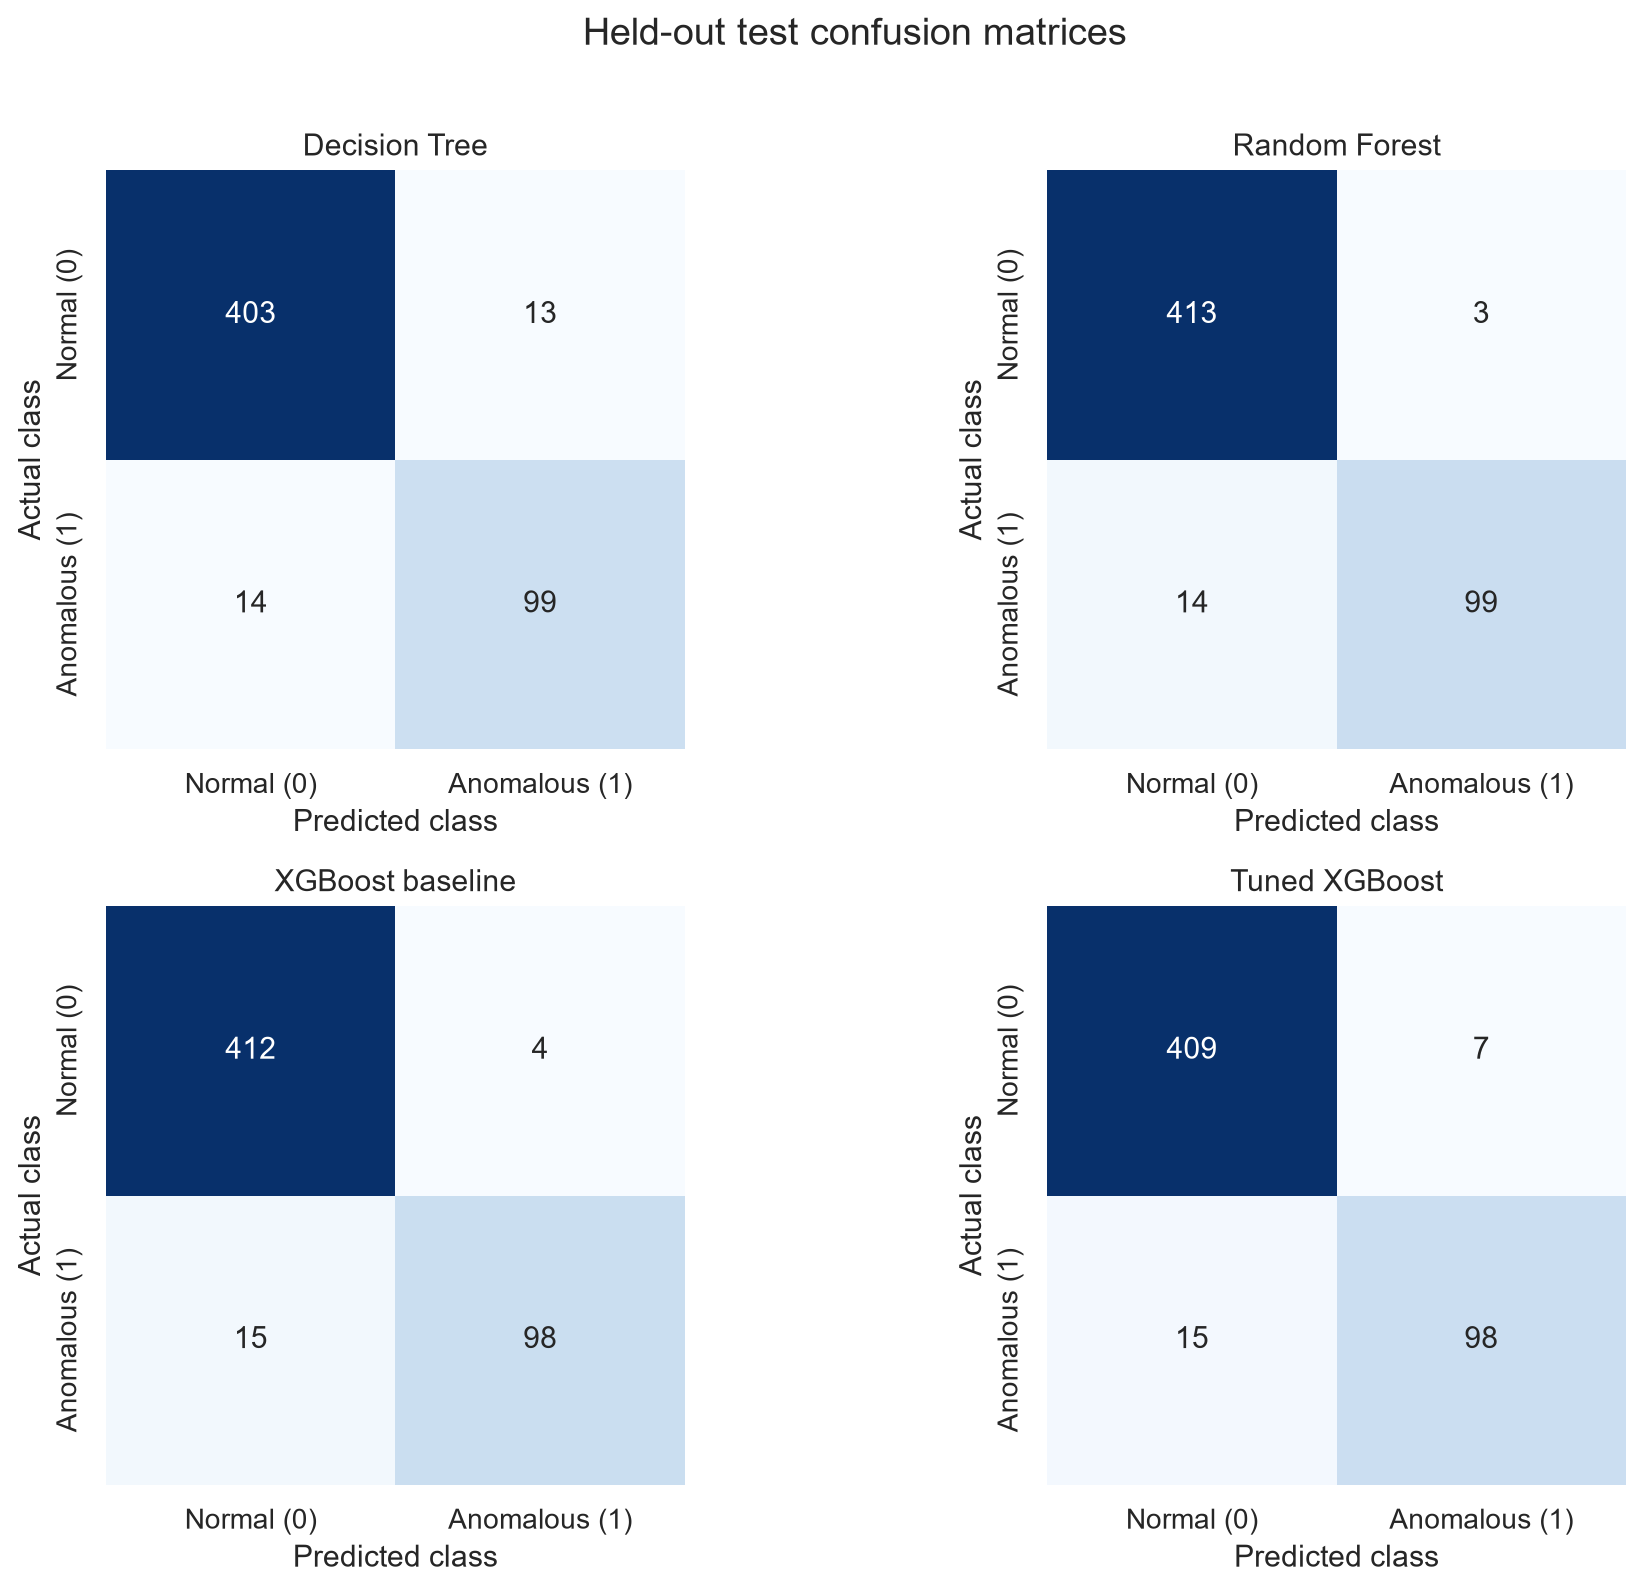

In [3]:
for model_name, result in evaluation["results"].items():
    counts = result["confusion_counts"]
    print(f"\n{model_name}")
    print(
        f"TN={counts['true_negative']}, FP={counts['false_positive']}, "
        f"FN={counts['false_negative']}, TP={counts['true_positive']}"
    )
    print("False-positive segment IDs:", result["false_positive_segment_ids"])
    print("False-negative segment IDs:", result["false_negative_segment_ids"])
    print("Classification report:")
    display(pd.DataFrame(result["classification_report"]).T.round(3))

confusion_figure = FIGURES_DIR / "confusion_matrix.png"
print("\nSaved confusion matrix:", confusion_figure)
display(Image(filename=str(confusion_figure)))

## 5. ROC and precision-recall curves

The ROC curve shows how true-positive rate (anomaly recall) changes against false-positive rate as the probability threshold varies. The precision-recall curve shows the precision/recall trade-off; its dashed reference is the test-set anomaly prevalence. These are threshold-independent views of the saved models' scores and do not change the classifiers or their predictions.

C:\Users\HP\OneDrive\Desktop\orbit gaurd\reports\figures\roc_curve.png


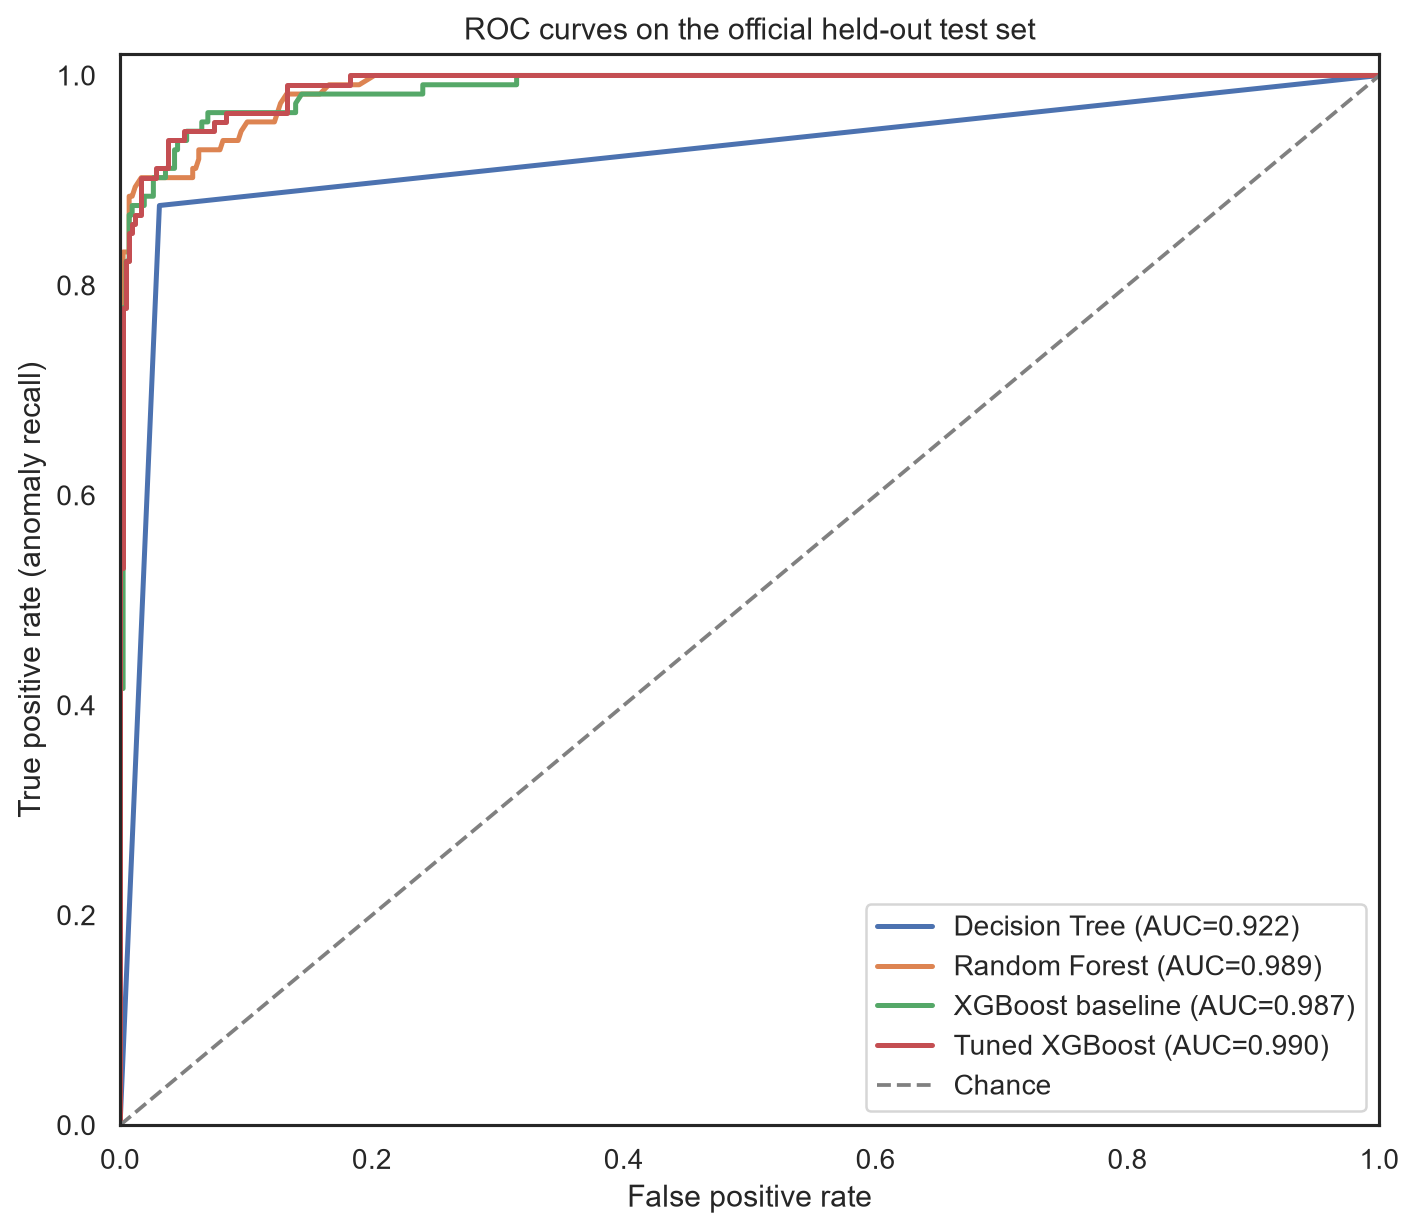

C:\Users\HP\OneDrive\Desktop\orbit gaurd\reports\figures\precision_recall_curve.png


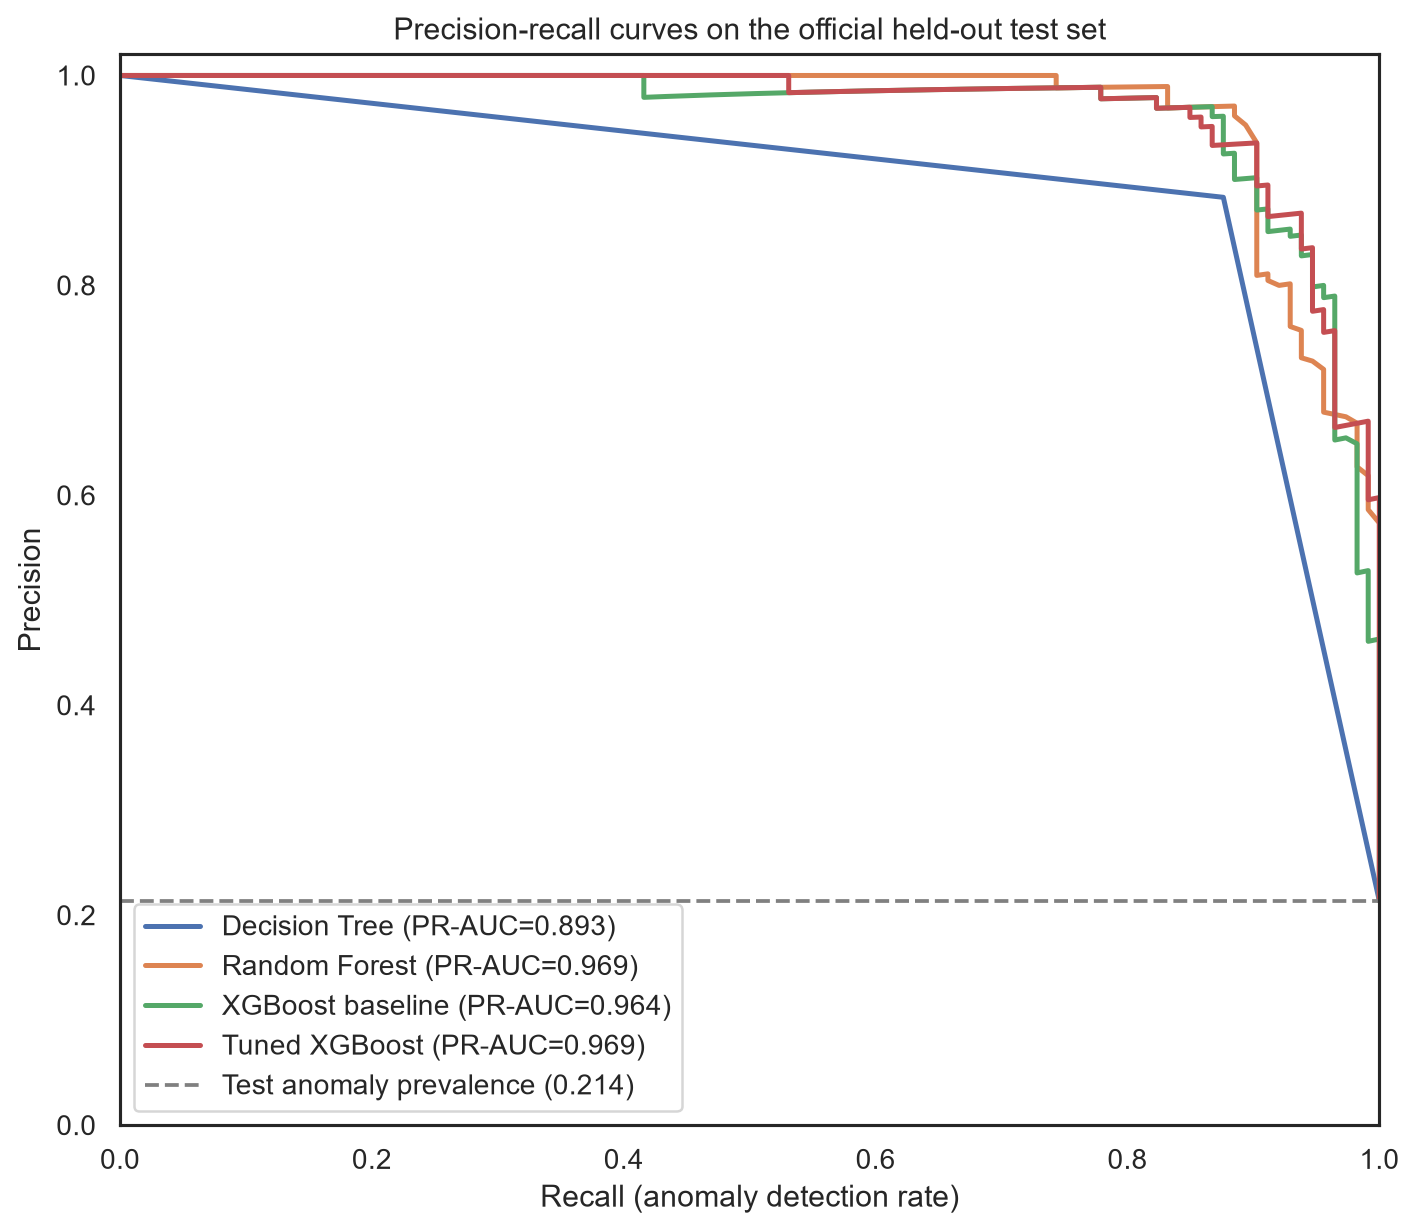

In [4]:
for figure_name in ["roc_curve.png", "precision_recall_curve.png"]:
    figure_path = FIGURES_DIR / figure_name
    print(figure_path)
    display(Image(filename=str(figure_path)))

## 6. Baseline versus tuned XGBoost

Hyperparameters were selected using training-only cross-validation in Stage 4. Here we compare the already-saved baseline and tuned XGBoost on the same untouched test set. Any performance difference is descriptive for this benchmark split; the test scores were not used to tune either model.

In [5]:
xgboost_comparison = comparison[comparison["model"].isin(["XGBoost baseline", "Tuned XGBoost"])].set_index("model")
display(xgboost_comparison.round(4))
baseline = xgboost_comparison.loc["XGBoost baseline"]
tuned = xgboost_comparison.loc["Tuned XGBoost"]
print(
    "Tuned minus baseline: "
    f"recall {tuned['recall_anomaly'] - baseline['recall_anomaly']:+.4f}, "
    f"F1 {tuned['f1_anomaly'] - baseline['f1_anomaly']:+.4f}, "
    f"PR-AUC {tuned['pr_auc'] - baseline['pr_auc']:+.4f}, "
    f"ROC-AUC {tuned['roc_auc'] - baseline['roc_auc']:+.4f}."
)

,accuracy,precision_anomaly,recall_anomaly,f1_anomaly,roc_auc,pr_auc,average_precision,true_negative,false_positive,false_negative,true_positive
model,,,,,,,,,,,
XGBoost baseline,0.9641,0.9608,0.8673,0.9116,0.9873,0.9641,0.9643,412,4,15,98
Tuned XGBoost,0.9584,0.9333,0.8673,0.8991,0.9900,0.9693,0.9695,409,7,15,98


Tuned minus baseline: recall +0.0000, F1 -0.0125, PR-AUC +0.0052, ROC-AUC +0.0026.


## 7. Evidence-based observations and report verification

The summary below is generated from the measured test-set results. The ranking criterion prioritizes anomaly recall and uses F1 and PR-AUC as tie-breakers. Read FP and FN counts before making an operational choice: false alarms and missed anomalies have different costs. The dashboard JSON and per-record predictions CSV are saved as reusable outputs.

In [6]:
best = comparison.iloc[0]
print(f"1. Highest anomaly recall under the stated ranking rule: {evaluation['best_model']} "
      f"({best['recall_anomaly']:.4f}; {int(best['true_positive'])} detected anomalies, "
      f"{int(best['false_negative'])} missed anomalies).")
rf = comparison.loc[comparison["model"].eq("Random Forest")].iloc[0]
print(f"2. Random Forest test anomaly precision/recall/F1: "
      f"{rf['precision_anomaly']:.4f}/{rf['recall_anomaly']:.4f}/{rf['f1_anomaly']:.4f}.")
print("3. Accuracy is only one part of the picture; use anomaly recall and the FP/FN "
      "counts to understand misses and false alarms.")

required_outputs = [
    REPORT_DIR / "model_performance.csv",
    REPORT_DIR / "classification_report.txt",
    REPORT_DIR / "evaluation_results.json",
    REPORT_DIR / "evaluation_predictions.csv",
    FIGURES_DIR / "confusion_matrix.png",
    FIGURES_DIR / "roc_curve.png",
    FIGURES_DIR / "precision_recall_curve.png",
]
print("\nSaved report files:")
for output_path in required_outputs:
    if not output_path.is_file() or output_path.stat().st_size == 0:
        raise FileNotFoundError(f"Expected evaluation output was not saved: {output_path}")
    print(f"- {output_path.relative_to(PROJECT_ROOT)} ({output_path.stat().st_size:,} bytes)")
print("\nStage 5 complete. No SHAP analysis or dashboard was started.")

1. Highest anomaly recall under the stated ranking rule: Random Forest (0.8761; 99 detected anomalies, 14 missed anomalies).
2. Random Forest test anomaly precision/recall/F1: 0.9706/0.8761/0.9209.
3. Accuracy is only one part of the picture; use anomaly recall and the FP/FN counts to understand misses and false alarms.

Saved report files:
- reports\evaluation\model_performance.csv (781 bytes)
- reports\evaluation\classification_report.txt (3,777 bytes)
- reports\evaluation\evaluation_results.json (8,067 bytes)
- reports\evaluation\evaluation_predictions.csv (111,761 bytes)
- reports\figures\confusion_matrix.png (137,911 bytes)
- reports\figures\roc_curve.png (112,049 bytes)
- reports\figures\precision_recall_curve.png (104,894 bytes)

Stage 5 complete. No SHAP analysis or dashboard was started.
